# Parse archived IMDb rating pages

Run all cells from the project root. This notebook reads each `ratings/*.html` file and writes one row per source page to `imdb_ratings.csv` in the project root. It supports the older rating/demographic tables, the later age-and-gender matrix, and IMDb's embedded `__NEXT_DATA__` histogram. Pages without usable statistics remain in the CSV with an explicit status; missing values are left blank.

In [1]:
from collections import Counter
from datetime import datetime
from html.parser import HTMLParser
from pathlib import Path
import csv
import json
import re

PROJECT_DIR = Path.cwd().resolve()
HTML_DIR = PROJECT_DIR / 'ratings'
OUTPUT_CSV = PROJECT_DIR / 'imdb_ratings.csv'
FILENAME_PATTERN = re.compile(r'^(\d{14})_(tt\d+)\.html$', re.IGNORECASE)

if not HTML_DIR.is_dir():
    raise FileNotFoundError(f'Expected the ratings folder at {HTML_DIR}. Run this notebook with the project root as the working directory.')


def clean_text(value):
    return ' '.join(str(value or '').split())


def decode_html(source):
    raw = source.read_bytes()
    charset = re.search(br'charset\s*=\s*["\']?([a-zA-Z0-9._-]+)', raw[:4096], re.IGNORECASE)
    encoding = charset.group(1).decode('ascii', errors='ignore') if charset else 'utf-8'
    try:
        return raw.decode(encoding)
    except (LookupError, UnicodeDecodeError):
        return raw.decode('utf-8', errors='replace')


class RatingPageParser(HTMLParser):
    def __init__(self):
        super().__init__(convert_charrefs=True)
        self.tables = []
        self.table_stack = []
        self.row_stack = []
        self.cell_stack = []
        self.title_parts = []
        self.in_title = False
        self.headings = []
        self.heading_stack = []
        self.anchors = []
        self.anchor_stack = []
        self.next_data_scripts = []
        self.active_script = None

    def handle_starttag(self, tag, attrs):
        attrs = dict(attrs)
        if tag == 'title':
            self.in_title = True
        elif tag in ('h1', 'h2'):
            self.heading_stack.append({'tag': tag, 'text': []})
        elif tag == 'a':
            self.anchor_stack.append({'href': attrs.get('href', ''), 'text': []})
        elif tag == 'table':
            table = {'attrs': attrs, 'rows': []}
            self.tables.append(table)
            self.table_stack.append(table)
        elif tag == 'tr' and self.table_stack:
            row = []
            self.table_stack[-1]['rows'].append(row)
            self.row_stack.append(row)
        elif tag in ('td', 'th') and self.row_stack:
            cell = {'tag': tag, 'attrs': attrs, 'text': []}
            self.row_stack[-1].append(cell)
            self.cell_stack.append(cell)
        elif tag == 'script' and attrs.get('id') == '__NEXT_DATA__':
            self.active_script = []
            self.next_data_scripts.append(self.active_script)

    def handle_endtag(self, tag):
        if tag == 'title':
            self.in_title = False
        elif tag in ('h1', 'h2') and self.heading_stack:
            heading = self.heading_stack.pop()
            self.headings.append(clean_text(' '.join(heading['text'])))
        elif tag == 'a' and self.anchor_stack:
            anchor = self.anchor_stack.pop()
            anchor['text'] = clean_text(' '.join(anchor['text']))
            self.anchors.append(anchor)
        elif tag in ('td', 'th') and self.cell_stack:
            self.cell_stack.pop()
        elif tag == 'tr' and self.row_stack:
            self.row_stack.pop()
        elif tag == 'table' and self.table_stack:
            self.table_stack.pop()
        elif tag == 'script' and self.active_script is not None:
            self.active_script = None

    def handle_data(self, data):
        if self.in_title:
            self.title_parts.append(data)
        if self.heading_stack:
            self.heading_stack[-1]['text'].append(data)
        if self.anchor_stack:
            self.anchor_stack[-1]['text'].append(data)
        if self.cell_stack:
            self.cell_stack[-1]['text'].append(data)
        if self.active_script is not None:
            self.active_script.append(data)


def cell_text(cell):
    return clean_text(' '.join(cell['text']))


def parse_count(value):
    if isinstance(value, bool) or value is None:
        return None
    if isinstance(value, (int, float)):
        return int(value) if value >= 0 else None
    text = clean_text(value)
    if re.search(r'\d\s*[kKmM]\b', text):
        return None
    match = re.search(r'\d[\d,]*', text)
    return int(match.group().replace(',', '')) if match else None


def parse_decimal(value):
    match = re.search(r'-?\d+(?:\.\d+)?', clean_text(value))
    return float(match.group()) if match else None


def parse_percentage(value):
    match = re.search(r'(\d+(?:\.\d+)?)\s*%', clean_text(value))
    return float(match.group(1)) if match else None


def parse_rating_number(value):
    match = re.fullmatch(r'\s*(10|[1-9])(?:\.0)?\s*', clean_text(value))
    return int(match.group(1)) if match else None


def parse_html_histogram(tables):
    candidates = []
    for table in tables:
        rows = table['rows']
        for header_index, header in enumerate(rows):
            labels = [cell_text(cell).casefold() for cell in header]
            rating_index = next((i for i, label in enumerate(labels) if label == 'rating'), None)
            votes_index = next((i for i, label in enumerate(labels) if label in ('votes', 'vote count', 'number of votes')), None)
            percentage_index = next((i for i, label in enumerate(labels) if 'percentage' in label or label == 'percent'), None)
            if rating_index is None or votes_index is None:
                continue
            counts = {}
            percentages = {}
            for row in rows[header_index + 1:]:
                if len(row) <= max(rating_index, votes_index):
                    continue
                rating = parse_rating_number(cell_text(row[rating_index]))
                votes = parse_count(cell_text(row[votes_index]))
                if rating is None or votes is None:
                    continue
                counts[rating] = votes
                if percentage_index is not None and len(row) > percentage_index:
                    percentage = parse_percentage(cell_text(row[percentage_index]))
                    if percentage is not None:
                        percentages[rating] = percentage
            if counts:
                candidates.append((counts, percentages))
    return max(candidates, key=lambda item: len(item[0])) if candidates else ({}, {})


def normalized_cohort(label):
    value = clean_text(label).casefold()
    known = {
        'males': 'males_all_ages',
        'females': 'females_all_ages',
        'aged under 18': 'all_under_18',
        'under 18': 'all_under_18',
        'males under 18': 'males_under_18',
        'males aged under 18': 'males_under_18',
        'females under 18': 'females_under_18',
        'females aged under 18': 'females_under_18',
        'aged 18-29': 'all_18_29',
        'males aged 18-29': 'males_18_29',
        'males 18-29': 'males_18_29',
        'females aged 18-29': 'females_18_29',
        'females 18-29': 'females_18_29',
        'aged 30-44': 'all_30_44',
        'males aged 30-44': 'males_30_44',
        'males 30-44': 'males_30_44',
        'females aged 30-44': 'females_30_44',
        'females 30-44': 'females_30_44',
        'aged 45+': 'all_45_plus',
        'males aged 45+': 'males_45_plus',
        'males 45+': 'males_45_plus',
        'females aged 45+': 'females_45_plus',
        'females 45+': 'females_45_plus',
        'all': 'all_all_ages',
        'all votes': 'all_all_ages',
        'top 1000 voters': 'top_1000_voters',
        'us users': 'us_users',
        'non-us users': 'non_us_users',
        'imdb staff': 'imdb_staff',
    }
    if value in known:
        return known[value]
    slug = re.sub(r'[^a-z0-9]+', '_', value).strip('_')
    return slug or 'unknown'


def normalized_group(label):
    value = clean_text(label).casefold()
    if value in ('all', 'all voters', 'all users'):
        return 'all'
    if value in ('male', 'males'):
        return 'males'
    if value in ('female', 'females'):
        return 'females'
    return re.sub(r'[^a-z0-9]+', '_', value).strip('_') or 'unknown'


def normalized_age(label):
    value = clean_text(label).casefold()
    known = {
        'all ages': 'all_ages',
        'all': 'all_ages',
        '<18': 'under_18',
        'under 18': 'under_18',
        '18-29': '18_29',
        '30-44': '30_44',
        '45+': '45_plus',
    }
    return known.get(value, re.sub(r'[^a-z0-9]+', '_', value).strip('_') or 'unknown')


def parse_average_and_votes(value):
    match = re.search(r'(\d+(?:\.\d+)?)\s+([\d,]+)', clean_text(value))
    if not match:
        return None, None
    return float(match.group(1)), int(match.group(2).replace(',', ''))


def parse_matrix_demographics(tables):
    result = {}
    for table in tables:
        rows = table['rows']
        for header_index, header in enumerate(rows):
            labels = [cell_text(cell) for cell in header]
            if 'All Ages' not in labels or not any(label in ('<18', '18-29', '30-44', '45+') for label in labels):
                continue
            for row in rows[header_index + 1:]:
                if not row:
                    continue
                group = normalized_group(cell_text(row[0]))
                if group not in ('all', 'males', 'females'):
                    continue
                for index, age_label in enumerate(labels[1:], start=1):
                    if index >= len(row):
                        continue
                    average, votes = parse_average_and_votes(cell_text(row[index]))
                    if average is None or votes is None:
                        continue
                    cohort = f'cohort_{group}_{normalized_age(age_label)}'
                    result[f'{cohort}_average'] = average
                    result[f'{cohort}_votes'] = votes
    return result


def parse_legacy_demographics(tables):
    result = {}
    for table in tables:
        rows = table['rows']
        for header_index, header in enumerate(rows):
            labels = [cell_text(cell).casefold() for cell in header]
            votes_index = next((i for i, label in enumerate(labels) if label == 'votes'), None)
            average_index = next((i for i, label in enumerate(labels) if label == 'average'), None)
            if votes_index is None or average_index is None:
                continue
            for row in rows[header_index + 1:]:
                if not row or len(row) <= max(votes_index, average_index):
                    continue
                label = cell_text(row[0])
                votes = parse_count(cell_text(row[votes_index]))
                average = parse_decimal(cell_text(row[average_index]))
                if not label or votes is None or average is None:
                    continue
                cohort = f'cohort_{normalized_cohort(label)}'
                result[f'{cohort}_votes'] = votes
                result[f'{cohort}_average'] = average
    return result


def parse_next_data(parser):
    errors = []
    for parts in parser.next_data_scripts:
        try:
            data = json.loads(''.join(parts))
        except json.JSONDecodeError:
            errors.append('Invalid __NEXT_DATA__ JSON')
            continue
        page_props = data.get('props', {}).get('pageProps', {})
        content = page_props.get('contentData', {})
        if isinstance(content, dict):
            return content, errors
    return {}, errors


def parse_json_histogram(content):
    histogram = content.get('histogramData') or {}
    counts = {}
    if isinstance(histogram, dict):
        for item in histogram.get('histogramValues', []):
            if not isinstance(item, dict):
                continue
            rating = parse_rating_number(item.get('rating'))
            votes = parse_count(item.get('voteCount'))
            if rating is not None and votes is not None:
                counts[rating] = votes
    return counts, histogram


def json_title(content):
    value = content.get('titleText', '')
    if isinstance(value, dict):
        value = value.get('text', '')
    if value:
        return clean_text(value)
    metadata = content.get('entityMetadata', {})
    value = metadata.get('titleText', {}) if isinstance(metadata, dict) else {}
    return clean_text(value.get('text', '')) if isinstance(value, dict) else ''


def clean_title(value):
    value = clean_text(value)
    value = re.sub(r'^user ratings?\s+(?:for\s+)?', '', value, flags=re.IGNORECASE)
    value = re.sub(r'\s+-\s+(?:user ratings|ratings)\b.*$', '', value, flags=re.IGNORECASE)
    value = re.sub(r'\s+-\s+IMDb\b.*$', '', value, flags=re.IGNORECASE)
    value = re.sub(r'\s+\((?:18|19|20)\d{2}\)$', '', value)
    return clean_text(value)


def page_title(parser, content, imdb_id):
    title = json_title(content)
    if title:
        return clean_title(title)
    title_pattern = re.compile(r'/title/' + re.escape(imdb_id) + r'(?:[/?#]|$)', re.IGNORECASE)
    for anchor in parser.anchors:
        if title_pattern.search(anchor.get('href', '')) and anchor.get('text'):
            return clean_title(anchor['text'])
    for heading in parser.headings:
        candidate = clean_title(heading)
        if candidate and candidate.casefold() not in ('ratings', 'user ratings'):
            return candidate
    return clean_title(' '.join(parser.title_parts))


def parse_page(source):
    match = FILENAME_PATTERN.fullmatch(source.name)
    if not match:
        raise ValueError(f'Unexpected rating filename: {source.name}')
    timestamp, imdb_id = match.groups()
    datetime.strptime(timestamp, '%Y%m%d%H%M%S')

    parser = RatingPageParser()
    parser.feed(decode_html(source))
    parser.close()
    content, json_errors = parse_next_data(parser)
    json_counts, histogram = parse_json_histogram(content)
    html_counts, html_percentages = parse_html_histogram(parser.tables)
    matrix_cohorts = parse_matrix_demographics(parser.tables)
    legacy_cohorts = parse_legacy_demographics(parser.tables)
    cohorts = {**legacy_cohorts, **matrix_cohorts}

    if json_counts:
        counts = json_counts
        percentages = {}
        page_format = 'embedded_json'
    else:
        counts = html_counts
        percentages = html_percentages
        if matrix_cohorts:
            page_format = 'demographic_matrix'
        elif html_counts or legacy_cohorts:
            page_format = 'legacy_table'
        elif parser.next_data_scripts:
            page_format = 'embedded_json'
        else:
            page_format = 'unknown'

    summary = histogram if isinstance(histogram, dict) else {}
    metadata = content.get('entityMetadata', {})
    rating_summary = metadata.get('ratingsSummary', {}) if isinstance(metadata, dict) else {}
    overall_rating = parse_decimal(summary.get('aggregateRating'))
    if overall_rating is None and isinstance(rating_summary, dict):
        overall_rating = parse_decimal(rating_summary.get('aggregateRating'))
    if overall_rating is None:
        overall_rating = cohorts.get('cohort_all_all_ages_average')

    total_votes = parse_count(summary.get('totalVoteCount'))
    if total_votes is None and isinstance(rating_summary, dict):
        total_votes = parse_count(rating_summary.get('voteCount'))
    if total_votes is None:
        total_votes = cohorts.get('cohort_all_all_ages_votes')
    if total_votes is None and set(counts) == set(range(1, 11)):
        total_votes = sum(counts.values())

    row = {
        'capture_timestamp': timestamp,
        'imdb_id': imdb_id,
        'title': page_title(parser, content, imdb_id),
        'overall_rating': overall_rating if overall_rating is not None else '',
        'total_votes': total_votes if total_votes is not None else '',
        'country_stats_json': '',
        'page_format': page_format,
        'parse_status': '',
        'parse_notes': '; '.join(json_errors),
        'source_file': source.relative_to(PROJECT_DIR).as_posix(),
    }

    if counts:
        complete_histogram = set(counts) == set(range(1, 11))
        for rating in range(1, 11):
            row[f'rating_{rating}_votes'] = counts.get(rating, 0) if complete_histogram else counts.get(rating, '')
            percentage = percentages.get(rating)
            if percentage is None and rating in counts and total_votes not in (None, 0):
                percentage = round(counts[rating] * 100 / total_votes, 4)
            row[f'rating_{rating}_percentage'] = percentage if percentage is not None else ''
    else:
        for rating in range(1, 11):
            row[f'rating_{rating}_votes'] = ''
            row[f'rating_{rating}_percentage'] = ''

    row.update(cohorts)
    country_data = summary.get('countryData', [])
    if isinstance(country_data, list) and country_data:
        row['country_stats_json'] = json.dumps(country_data, ensure_ascii=False, separators=(',', ':'))

    title_lower = row['title'].casefold()
    if title_lower == 'web.archive.org' or 'wayback machine' in title_lower:
        row['parse_status'] = 'unavailable_page'
    elif len(counts) == 10:
        row['parse_status'] = 'ok'
    elif counts:
        row['parse_status'] = 'partial'
        note = f'Found {len(counts)} of 10 rating buckets'
        row['parse_notes'] = '; '.join(filter(None, (row['parse_notes'], note)))
    else:
        row['parse_status'] = 'missing_ratings'

    return row


html_files = sorted(HTML_DIR.glob('*.html'))
if not html_files:
    raise FileNotFoundError(f'No HTML files found in {HTML_DIR}')

rows = []
for index, source in enumerate(html_files, start=1):
    rows.append(parse_page(source))
    if index % 500 == 0 or index == len(html_files):
        print(f'Parsed {index:,}/{len(html_files):,} HTML pages')

source_files = [row['source_file'] for row in rows]
if len(rows) != len(html_files):
    raise RuntimeError(f'Expected one row per HTML file: {len(html_files)} files, {len(rows)} rows')
if len(source_files) != len(set(source_files)):
    raise RuntimeError('Duplicate source_file values detected; refusing to write an ambiguous CSV')

rating_fields = [field for rating in range(1, 11) for field in (f'rating_{rating}_votes', f'rating_{rating}_percentage')]
cohort_fields = sorted({field for row in rows for field in row if field.startswith('cohort_')})
fieldnames = [
    'capture_timestamp', 'imdb_id', 'title', 'overall_rating', 'total_votes',
    *rating_fields, *cohort_fields, 'country_stats_json', 'page_format',
    'parse_status', 'parse_notes', 'source_file',
]

with OUTPUT_CSV.open('w', newline='', encoding='utf-8') as output:
    writer = csv.DictWriter(output, fieldnames=fieldnames, extrasaction='raise')
    writer.writeheader()
    writer.writerows(rows)

with OUTPUT_CSV.open(newline='', encoding='utf-8') as output:
    exported_rows = sum(1 for _ in csv.DictReader(output))
if exported_rows != len(html_files):
    raise RuntimeError(f'CSV verification failed: expected {len(html_files)} rows, found {exported_rows}')

status_counts = Counter(row['parse_status'] for row in rows)
format_counts = Counter(row['page_format'] for row in rows)
print(f'\nWrote {exported_rows:,} rows and {len(fieldnames):,} columns to {OUTPUT_CSV}')
print('Parse statuses:', dict(sorted(status_counts.items())))
print('Page formats:', dict(sorted(format_counts.items())))
missing_rows = [row for row in rows if row['parse_status'] != 'ok']
if missing_rows:
    print('\nPages needing review (first 20):')
    for row in missing_rows[:20]:
        print(f"{row['parse_status']}: {row['source_file']}")


Parsed 500/6,079 HTML pages
Parsed 1,000/6,079 HTML pages
Parsed 1,500/6,079 HTML pages
Parsed 2,000/6,079 HTML pages
Parsed 2,500/6,079 HTML pages
Parsed 3,000/6,079 HTML pages
Parsed 3,500/6,079 HTML pages
Parsed 4,000/6,079 HTML pages
Parsed 4,500/6,079 HTML pages
Parsed 5,000/6,079 HTML pages
Parsed 5,500/6,079 HTML pages
Parsed 6,000/6,079 HTML pages
Parsed 6,079/6,079 HTML pages

Wrote 6,079 rows and 70 columns to /Users/surenpoghosian/Data_mining/Project/imdb_ratings.csv
Parse statuses: {'missing_ratings': 26, 'ok': 6041, 'partial': 12}
Page formats: {'demographic_matrix': 1677, 'embedded_json': 711, 'legacy_table': 3666, 'unknown': 25}

Pages needing review (first 20):
missing_ratings: ratings/20060326114520_tt0381061.html
missing_ratings: ratings/20070315014831_tt0042546.html
partial: ratings/20071015163657_tt0861739.html
partial: ratings/20071103020846_tt0467406.html
partial: ratings/20071228020555_tt0986264.html
missing_ratings: ratings/20080423204054_tt0371746.html
missing_

____Head____


,capture_timestamp,imdb_id,title,overall_rating,total_votes,rating_1_votes,rating_1_percentage,rating_2_votes,rating_2_percentage,rating_3_votes,rating_3_percentage,rating_4_votes,rating_4_percentage,rating_5_votes,rating_5_percentage,...,cohort_males_all_ages_average,cohort_males_all_ages_votes,cohort_males_under_18_average,cohort_males_under_18_votes,cohort_non_us_users_average,cohort_non_us_users_votes,cohort_top_1000_voters_average,cohort_top_1000_voters_votes,cohort_us_users_average,cohort_us_users_votes,country_stats_json,page_format,parse_status,parse_notes,source_file
0,20050102124936,tt0026778,register,8.1,5493.0,111.0,2.0,31.0,0.6,31.0,0.6,60.0,1.1,184.0,3.3,...,8.1,3308.0,8.8,63.0,8.0,1630.0,7.9,453.0,8.2,2128.0,NaN,legacy_table,ok,NaN,ratings/20050102124936_tt0026778.html
1,20050105210447,tt0070510,register,7.7,2972.0,20.0,0.7,13.0,0.4,18.0,0.6,37.0,1.2,118.0,4.0,...,7.7,1607.0,9.4,17.0,7.6,709.0,7.5,399.0,7.8,1268.0,NaN,legacy_table,ok,NaN,ratings/20050105210447_tt0070510.html
2,20050106014719,tt0325710,register,7.9,27071.0,549.0,2.0,176.0,0.7,229.0,0.8,377.0,1.4,765.0,2.8,...,7.9,19141.0,8.5,1094.0,7.8,12923.0,7.1,405.0,8.1,8676.0,NaN,legacy_table,ok,NaN,ratings/20050106014719_tt0325710.html
3,20050106053840,tt0033870,register,8.4,18102.0,245.0,1.4,68.0,0.4,116.0,0.6,186.0,1.0,442.0,2.4,...,8.4,10385.0,8.3,176.0,8.2,4881.0,8.4,676.0,8.5,6974.0,NaN,legacy_table,ok,NaN,ratings/20050106053840_tt0033870.html
4,20050109034550,tt0046912,register,7.8,7360.0,46.0,0.6,17.0,0.2,20.0,0.3,50.0,0.7,207.0,2.8,...,7.8,4013.0,8.4,58.0,7.8,2350.0,7.6,580.0,7.8,2462.0,NaN,legacy_table,ok,NaN,ratings/20050109034550_tt0046912.html


____Tail____


,capture_timestamp,imdb_id,title,overall_rating,total_votes,rating_1_votes,rating_1_percentage,rating_2_votes,rating_2_percentage,rating_3_votes,rating_3_percentage,rating_4_votes,rating_4_percentage,rating_5_votes,rating_5_percentage,...,cohort_males_all_ages_average,cohort_males_all_ages_votes,cohort_males_under_18_average,cohort_males_under_18_votes,cohort_non_us_users_average,cohort_non_us_users_votes,cohort_top_1000_voters_average,cohort_top_1000_voters_votes,cohort_us_users_average,cohort_us_users_votes,country_stats_json,page_format,parse_status,parse_notes,source_file
6074,20251222180003,tt1877832,X-Men: Days of Future Past,7.9,781031.0,4578.0,0.5861,1825.0,0.2337,2802.0,0.3588,5652.0,0.7237,15762.0,2.0181,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[{""displayText"":""United States"",""aggregateRati...",embedded_json,ok,NaN,ratings/20251222180003_tt1877832.html
6075,20251225195107,tt2802144,Kingsman: The Secret Service,7.7,767604.0,5688.0,0.7410,3165.0,0.4123,4809.0,0.6265,9025.0,1.1757,22407.0,2.9191,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[{""displayText"":""United States"",""aggregateRati...",embedded_json,ok,NaN,ratings/20251225195107_tt2802144.html
6076,20251229123826,tt0077711,Autumn Sonata,8.1,41468.0,573.0,1.3818,366.0,0.8826,417.0,1.0056,544.0,1.3119,1023.0,2.4670,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[{""displayText"":""United States"",""aggregateRati...",embedded_json,ok,NaN,ratings/20251229123826_tt0077711.html
6077,20251231211132,tt0407887,The Departed,8.5,1531829.0,10105.0,0.6597,3620.0,0.2363,4592.0,0.2998,7971.0,0.5204,18215.0,1.1891,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[{""displayText"":""United States"",""aggregateRati...",embedded_json,ok,NaN,ratings/20251231211132_tt0407887.html
6078,20251231211153,tt0440963,The Bourne Ultimatum,8.0,679065.0,4799.0,0.7067,1835.0,0.2702,2682.0,0.3950,4661.0,0.6864,12227.0,1.8006,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[{""displayText"":""United States"",""aggregateRati...",embedded_json,ok,NaN,ratings/20251231211153_tt0440963.html


____Info____
<class 'pandas.DataFrame'>
RangeIndex: 6079 entries, 0 to 6078
Data columns (total 70 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   capture_timestamp                6079 non-null   int64  
 1   imdb_id                          6079 non-null   str    
 2   title                            6079 non-null   str    
 3   overall_rating                   3256 non-null   float64
 4   total_votes                      6045 non-null   float64
 5   rating_1_votes                   6052 non-null   float64
 6   rating_1_percentage              6052 non-null   float64
 7   rating_2_votes                   6046 non-null   float64
 8   rating_2_percentage              6046 non-null   float64
 9   rating_3_votes                   6049 non-null   float64
 10  rating_3_percentage              6049 non-null   float64
 11  rating_4_votes                   6047 non-null   float64
 12  rating_4_percentag

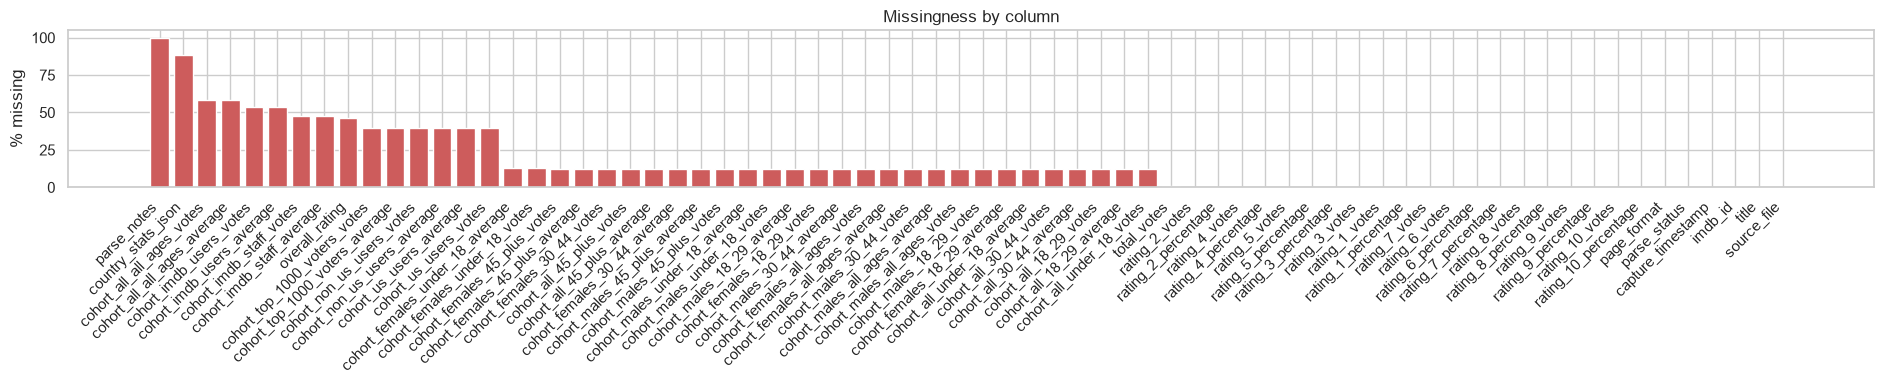

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True
pd.set_option("display.max_columns", 30)


# print("numpy version   :", np.__version__)
# print("pandas version  :", pd.__version__)
# print("seaborn version :", sns.__version__)

df = pd.read_csv("imdb_ratings.csv")

print("____Head____")
display(df.head())

print("____Tail____")
display(df.tail())


print("____Info____")
df_info = df.info()

# display(df_info)

df_copy = df.copy()

print("========================================")
print(df_copy.isnull().sum().sort_values(ascending=False))
print("========================================")
print("\nTotal Missing - ", df_copy.isnull().sum().sum())
print("\nTotal number of values in the data (rows x columns)", len(df_copy)*len(df_copy.columns))
print("\nMissing % - ", df_copy.isnull().sum().sum() / df_copy.size * 100)
print("========================================")
print("\nduplicated - ", df_copy.duplicated().sum())

missing_pct = df_copy.isnull().mean().sort_values(ascending=False) * 100
plt.figure(figsize=(19, 4))
plt.bar(missing_pct.index, missing_pct.values, color="indianred")
plt.ylabel("% missing")
plt.title("Missingness by column")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


df_copy['imdb_id'].unique()

df_export = df_copy[['imdb_id', 'title']].drop_duplicates(subset='imdb_id')